# ⏰ Notebook 5: Circadian Rhythm & Time-of-Day (MLP Neural Network)

## 1. Physiological Context & Plant Circadian Clock
Diurnal biopotential baseline variations (`morning`, `afternoon`, `night`).
All generated plots are saved to `plot/05_circadian_rhythm_mlp_neural_network/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "05_circadian_rhythm_mlp_neural_network"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
    DATA_PATH = "plant_time_series_features.csv"
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
    DATA_PATH = os.path.join("notebook", "plant_time_series_features.csv") if os.path.exists(os.path.join("notebook", "plant_time_series_features.csv")) else "plant_time_series_features.csv"

os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")

df = pd.read_csv(DATA_PATH)
print("Time of Day Counts:", df["time_of_day"].value_counts())


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\05_circadian_rhythm_mlp_neural_network
Time of Day Counts: time_of_day
afternoon    1576
morning      1461
night         492
Name: count, dtype: int64


## 2. Diurnal Baseline Shift Across the 24-Hour Cycle

C:\Users\asim\AppData\Local\Temp\ipykernel_2908\4189535807.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="time_of_day", y="mean", order=order, ax=ax1, palette=palette)
C:\Users\asim\AppData\Local\Temp\ipykernel_2908\4189535807.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="time_of_day", y="var", order=order, ax=ax2, palette=palette)


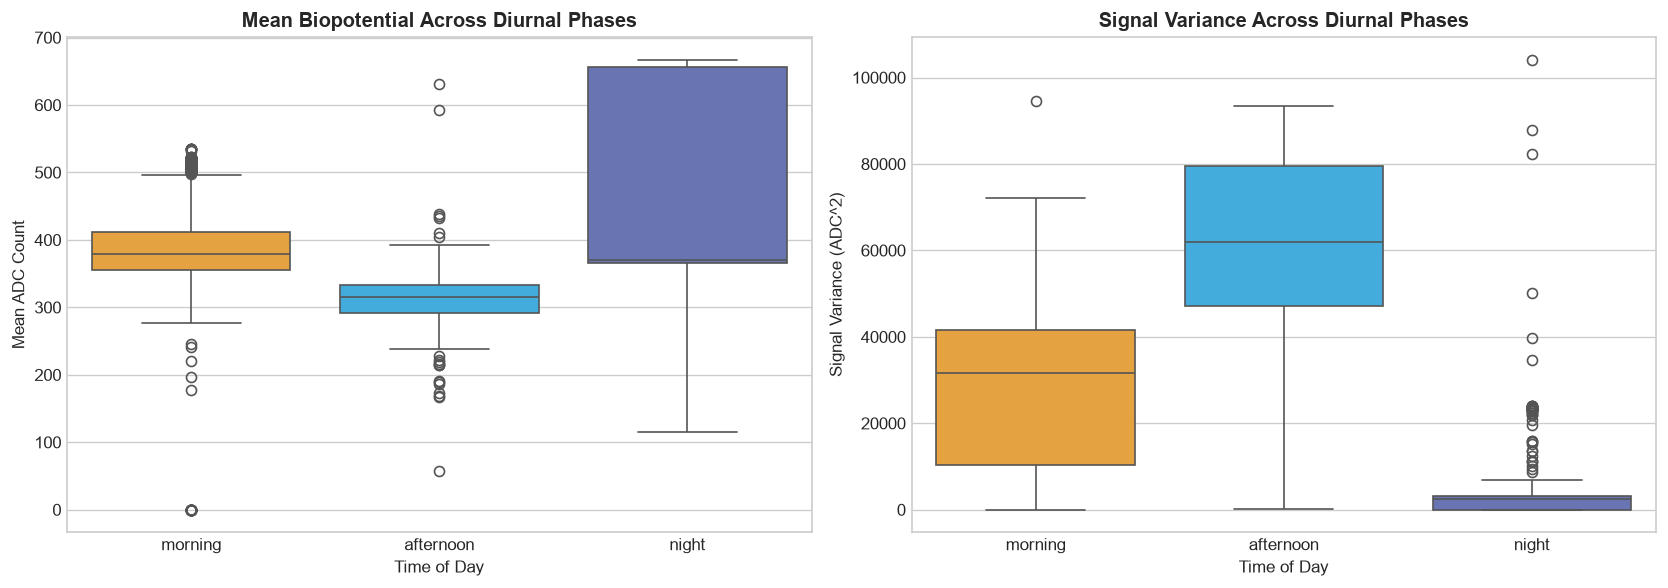

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
order = ["morning", "afternoon", "night"]
palette = {"morning": "#FFA726", "afternoon": "#29B6F6", "night": "#5C6BC0"}

sns.boxplot(data=df, x="time_of_day", y="mean", order=order, ax=ax1, palette=palette)
ax1.set_title("Mean Biopotential Across Diurnal Phases", fontweight='bold')
ax1.set_ylabel("Mean ADC Count")
ax1.set_xlabel("Time of Day")

sns.boxplot(data=df, x="time_of_day", y="var", order=order, ax=ax2, palette=palette)
ax2.set_title("Signal Variance Across Diurnal Phases", fontweight='bold')
ax2.set_ylabel("Signal Variance (ADC^2)")
ax2.set_xlabel("Time of Day")

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_diurnal_baseline_shifts.png"), dpi=300, bbox_inches='tight')
plt.show()


## 3. Train Multi-Layer Perceptron (MLP Neural Network)

In [3]:
feature_cols = [
    "mean", "std", "var", "min", "max", "range", "median", 
    "rms", "mad", "p25", "p75", "iqr", "zcr", "skew", "kurt", 
    "peak_count", "low_freq_power", "mid_freq_power", "high_freq_power", 
    "spectral_entropy", "dominant_freq"
]

time_phases = ["morning", "afternoon", "night"]
time_to_idx = {t: i for i, t in enumerate(time_phases)}

X = df[feature_cols].values
y = df["time_of_day"].map(time_to_idx).values
groups = df["session_id"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', max_iter=300, random_state=42, early_stopping=True)

oof_preds_mlp = np.zeros(len(y), dtype=int)
for fold, (tr_idx, te_idx) in enumerate(sgkf.split(X_scaled, y, groups)):
    mlp.fit(X_scaled[tr_idx], y[tr_idx])
    oof_preds_mlp[te_idx] = mlp.predict(X_scaled[te_idx])

print("=== MLP Neural Network Report ===")
print(classification_report(y, oof_preds_mlp, target_names=time_phases))


=== MLP Neural Network Report ===
              precision    recall  f1-score   support

     morning       0.91      0.56      0.70      1461
   afternoon       0.67      0.96      0.79      1576
       night       0.52      0.39      0.44       492

    accuracy                           0.72      3529
   macro avg       0.70      0.64      0.64      3529
weighted avg       0.75      0.72      0.70      3529



## 4. Circadian Confusion Matrix Heatmap

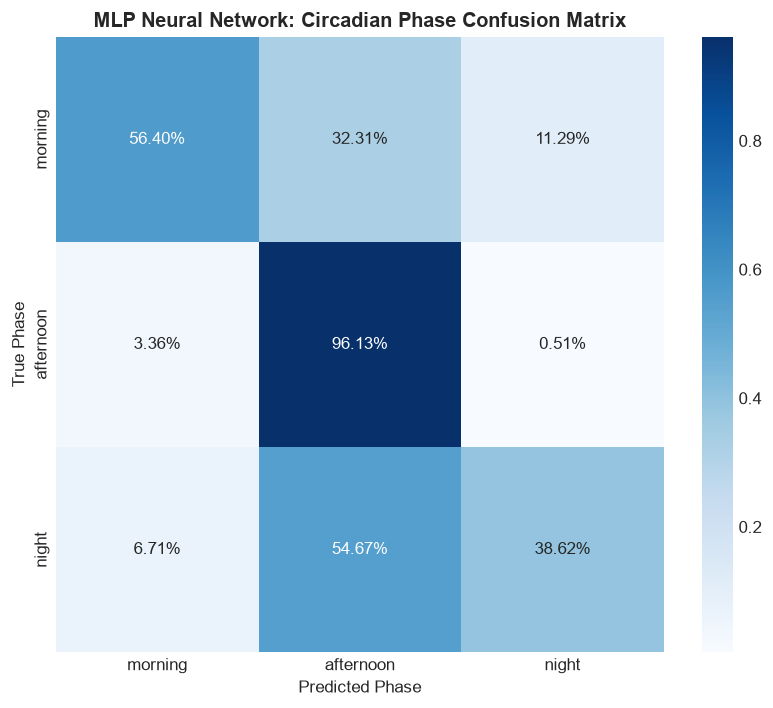

In [4]:
plt.figure(figsize=(7, 6))
cm_circ = confusion_matrix(y, oof_preds_mlp, normalize='true')
sns.heatmap(cm_circ, annot=True, fmt=".2%", cmap="Blues", xticklabels=time_phases, yticklabels=time_phases)
plt.title("MLP Neural Network: Circadian Phase Confusion Matrix", fontweight='bold')
plt.ylabel("True Phase")
plt.xlabel("Predicted Phase")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_circadian_confusion_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. Neural Network Training Loss Curve

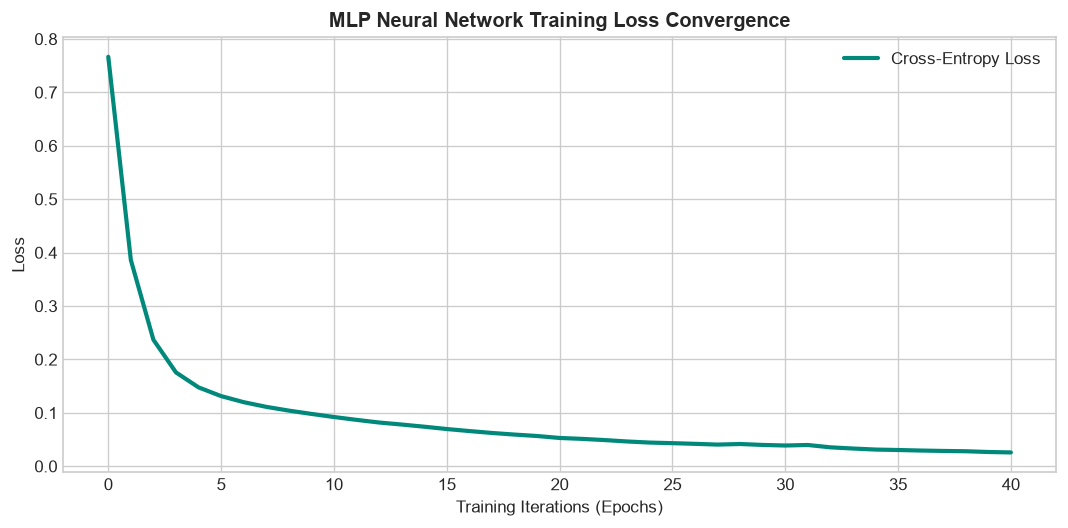

In [5]:
plt.figure(figsize=(9, 4.5))
plt.plot(mlp.loss_curve_, color='#00897B', lw=2.5, label='Cross-Entropy Loss')
plt.title("MLP Neural Network Training Loss Convergence", fontweight='bold')
plt.xlabel("Training Iterations (Epochs)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_mlp_training_loss.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. First Hidden Layer Weight Activations

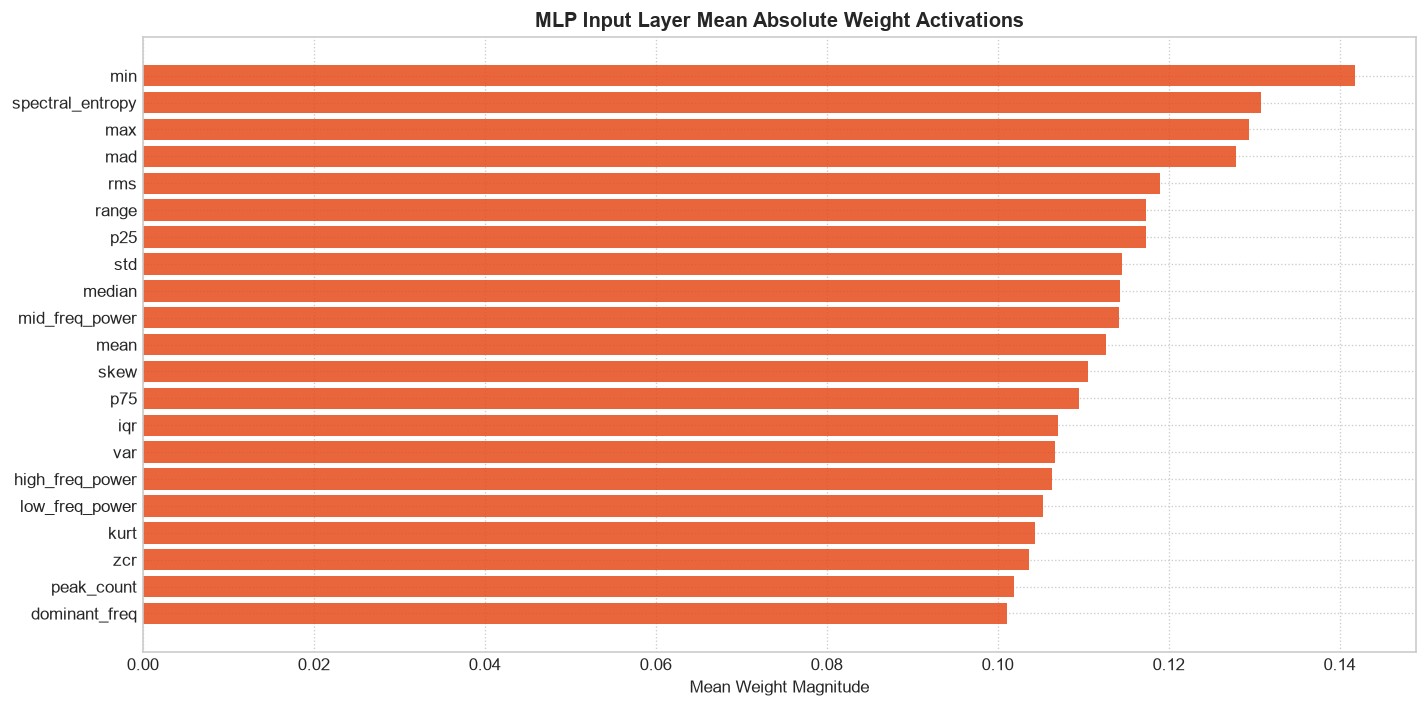

In [6]:
plt.figure(figsize=(12, 6))
weights_first_layer = np.abs(mlp.coefs_[0]).mean(axis=1)
indices = np.argsort(weights_first_layer)[::-1]

plt.barh(range(len(feature_cols)), weights_first_layer[indices][::-1], color='#E64A19', alpha=0.85)
plt.yticks(range(len(feature_cols)), [feature_cols[i] for i in indices][::-1])
plt.title("MLP Input Layer Mean Absolute Weight Activations", fontweight='bold')
plt.xlabel("Mean Weight Magnitude")
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_layer_weight_activations.png"), dpi=300, bbox_inches='tight')
plt.show()
